In [1]:
!pip install -q kagglehub

import os, time, glob
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from PIL import Image
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
path = kagglehub.dataset_download("tongpython/cat-and-dog")
print("Path dataset:", path)

Using Colab cache for faster access to the 'cat-and-dog' dataset.
Path dataset: /kaggle/input/cat-and-dog


In [3]:
def find_dir(root, name):
    for dirpath, dirnames, _ in os.walk(root):
        if os.path.basename(dirpath) == name and "cats" in dirnames and "dogs" in dirnames:
            return dirpath
    raise FileNotFoundError(name)

train_dir = find_dir(path, "training_set")
test_dir = find_dir(path, "test_set")
print(train_dir); print(test_dir)

/kaggle/input/cat-and-dog/training_set/training_set
/kaggle/input/cat-and-dog/test_set/test_set


In [4]:
def clean_corrupt(folder):
    corrupt_count = 0
    # Memfilter file agar hanya mendeteksi format gambar umum
    valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp')
    for f in glob.glob(os.path.join(folder, "*", "*")):
        if f.lower().endswith(valid_extensions):
            try:
                with Image.open(f) as im:
                    im.verify()
            except Exception:
                print(f"Gambar rusak ditemukan: {f}")
                corrupt_count += 1
        else:
            # Mengabaikan file sistem non-gambar seperti .DS_Store tanpa error
            pass
    print(f"{folder}: Ditemukan {corrupt_count} gambar rusak (tidak dihapus karena filesystem read-only)")

clean_corrupt(train_dir)
clean_corrupt(test_dir)

/kaggle/input/cat-and-dog/training_set/training_set: Ditemukan 0 gambar rusak (tidak dihapus karena filesystem read-only)
/kaggle/input/cat-and-dog/test_set/test_set: Ditemukan 0 gambar rusak (tidak dihapus karena filesystem read-only)


In [5]:
IMG, BS = (160, 160), 32
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, validation_split=0.2, subset="training", seed=42,
    image_size=IMG, batch_size=BS, label_mode="binary")
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, validation_split=0.2, subset="validation", seed=42,
    image_size=IMG, batch_size=BS, label_mode="binary")
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=IMG, batch_size=BS, shuffle=False, label_mode="binary")
class_names = train_ds.class_names
print(class_names)

Found 8005 files belonging to 2 classes.
Using 6404 files for training.
Found 8005 files belonging to 2 classes.
Using 1601 files for validation.
Found 2023 files belonging to 2 classes.
['cats', 'dogs']


In [6]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

In [7]:
# ===== 2. Model 1: CNN dari nol =====
def build_cnn():
    return models.Sequential([
        layers.Input(shape=IMG + (3,)),
        augment,
        layers.Rescaling(1./255),
        layers.Conv2D(32, 3, activation="relu"), layers.BatchNormalization(), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation="relu"), layers.BatchNormalization(), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation="relu"), layers.BatchNormalization(), layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(128, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ], name="CNN_scratch")

# ===== 3. Model 2: Transfer Learning (MobileNetV2) =====
def build_tl():
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=IMG + (3,), include_top=False, weights="imagenet")
    base_model.trainable = False
    return models.Sequential([
        layers.Input(shape=IMG + (3,)),
        augment,
        layers.Rescaling(1./127.5, offset=-1),
        base_model,
        layers.GlobalAveragePooling2D(),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ], name="MobileNetV2_TL")

In [8]:
# ===== 4. Training =====
def train(model, epochs=30):
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="binary_crossentropy", metrics=["accuracy"])
    cb = [tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)]
    t0 = time.time()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=cb)
    return hist, time.time() - t0

cnn = build_cnn()
hist_cnn, time_cnn = train(cnn)

tl = build_tl()
hist_tl, time_tl = train(tl)

Epoch 1/30
201/201 ━━━━━━━━━━━━━━━━━━━━ 23s 75ms/step - accuracy: 0.5978 - loss: 0.8706 - val_accuracy: 0.4934 - val_loss: 0.8161
Epoch 2/30
201/201 ━━━━━━━━━━━━━━━━━━━━ 15s 76ms/step - accuracy: 0.6716 - loss: 0.5980 - val_accuracy: 0.6415 - val_loss: 0.6831
Epoch 3/30
201/201 ━━━━━━━━━━━━━━━━━━━━ 15s 75ms/step - accuracy: 0.7044 - loss: 0.5633 - val_accuracy: 0.6696 - val_loss: 0.7247
Epoch 4/30
201/201 ━━━━━━━━━━━━━━━━━━━━ 15s 73ms/step - accuracy: 0.7052 - loss: 0.5669 - val_accuracy: 0.6721 - val_loss: 0.6093
Epoch 5/30
201/201 ━━━━━━━━━━━━━━━━━━━━ 15s 77ms/step - accuracy: 0.7461 - loss: 0.5075 - val_accuracy: 0.7452 - val_loss: 0.5589
Epoch 6/30
201/201 ━━━━━━━━━━━━━━━━━━━━ 20s 76ms/step - accuracy: 0.7439 - loss: 0.5321 - val_accuracy: 0.5821 - val_loss: 1.7763
Epoch 7/30
201/201 ━━━━━━━━━━━━━━━━━━━━ 15s 75ms/step - accuracy: 0.7634 - loss: 0.4918 - val_accuracy: 0.7701 - val_loss: 0.4944
Epoch 8/30
201/201 ━━━━━━━━━━━━━━━━━━━━ 15s 76ms/step - accuracy: 0.7795 - loss: 0.4518 - 

64/64 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step

=== CNN dari nol ===
              precision    recall  f1-score   support

        cats       0.75      0.80      0.77      1011
        dogs       0.78      0.73      0.75      1012

    accuracy                           0.76      2023
   macro avg       0.76      0.76      0.76      2023
weighted avg       0.76      0.76      0.76      2023



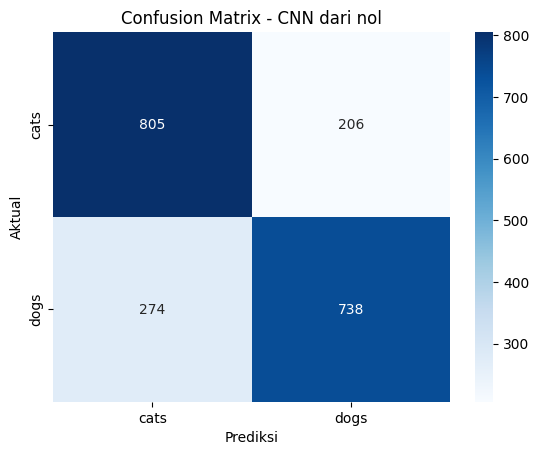

64/64 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step

=== MobileNetV2 (Transfer Learning) ===
              precision    recall  f1-score   support

        cats       0.99      0.99      0.99      1011
        dogs       0.99      0.99      0.99      1012

    accuracy                           0.99      2023
   macro avg       0.99      0.99      0.99      2023
weighted avg       0.99      0.99      0.99      2023



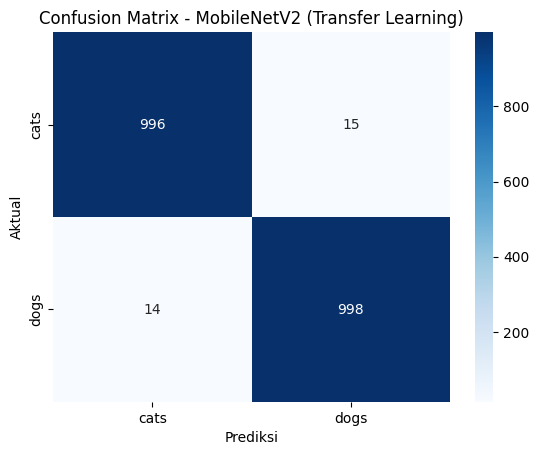

In [9]:
# ===== 5. Evaluasi =====
def evaluate(model, name):
    y_true = np.concatenate([y.numpy() for _, y in test_ds]).ravel().astype(int)
    y_prob = model.predict(test_ds).ravel()
    y_pred = (y_prob > 0.5).astype(int)
    print(f"\n=== {name} ===")
    print(classification_report(y_true, y_pred, target_names=class_names))
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Prediksi"); plt.ylabel("Aktual")
    plt.show()
    return (y_true == y_pred).mean()

acc_cnn = evaluate(cnn, "CNN dari nol")
acc_tl = evaluate(tl, "MobileNetV2 (Transfer Learning)")

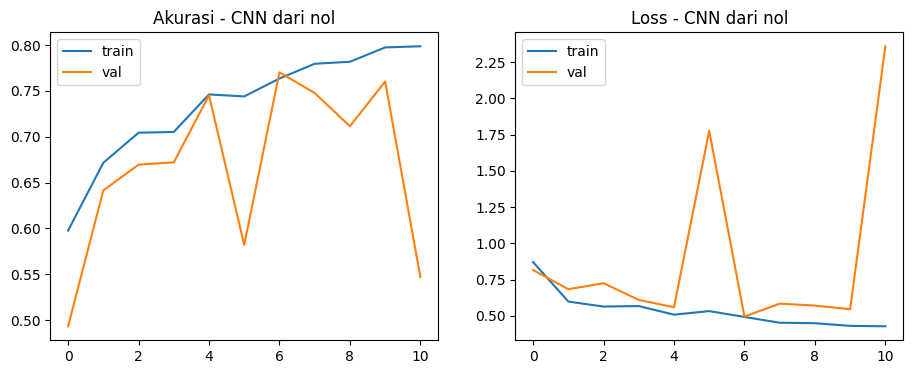

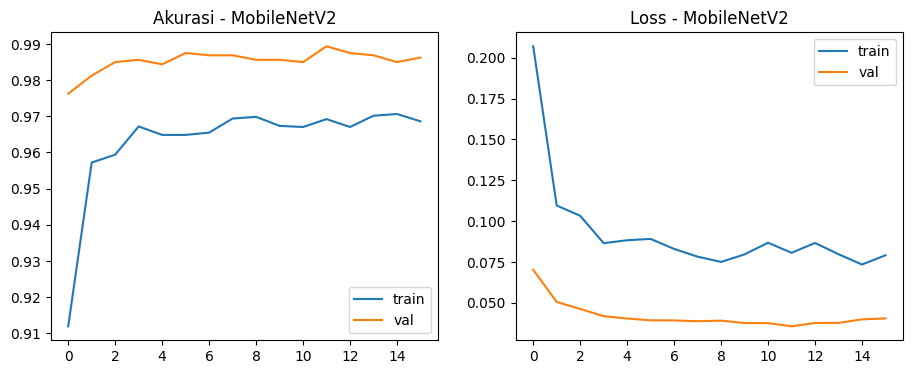

Model                    Parameter   Waktu (s)   Akurasi Uji
CNN dari nol             5,402,817       185.3        0.7627
MobileNetV2 (TL)         2,259,265       237.2        0.9857


In [10]:
# ===== 6. Kurva & Tabel Perbandingan =====
def plot_hist(h, name):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(h.history["accuracy"], label="train")
    ax[0].plot(h.history["val_accuracy"], label="val")
    ax[0].set_title(f"Akurasi - {name}"); ax[0].legend()
    ax[1].plot(h.history["loss"], label="train")
    ax[1].plot(h.history["val_loss"], label="val")
    ax[1].set_title(f"Loss - {name}"); ax[1].legend()
    plt.show()

plot_hist(hist_cnn, "CNN dari nol")
plot_hist(hist_tl, "MobileNetV2")

print(f"{'Model':<22}{'Parameter':>12}{'Waktu (s)':>12}{'Akurasi Uji':>14}")
print(f"{'CNN dari nol':<22}{cnn.count_params():>12,}{time_cnn:>12.1f}{acc_cnn:>14.4f}")
print(f"{'MobileNetV2 (TL)':<22}{tl.count_params():>12,}{time_tl:>12.1f}{acc_tl:>14.4f}")

# ===== 7. Simpan model =====
cnn.save("cnn_scratch.keras")
tl.save("mobilenetv2_tl.keras")

In [12]:
# ===== 8. Tampilkan Hasil Prediksi per Model =====
os.makedirs("results", exist_ok=True)

# Muat seluruh data uji sebagai array (uint8 agar hemat memori)
X_test = np.concatenate([x.numpy().astype("uint8") for x, _ in test_ds])
y_test = np.concatenate([y.numpy() for _, y in test_ds]).ravel().astype(int)

# Prediksi kedua model (model sudah memuat layer Rescaling, jadi input tetap 0-255)
prob_cnn = cnn.predict(X_test.astype("float32"), batch_size=32).ravel()
prob_tl = tl.predict(X_test.astype("float32"), batch_size=32).ravel()
pred_cnn = (prob_cnn > 0.5).astype(int)
pred_tl = (prob_tl > 0.5).astype(int)

def label_conf(prob):
    """Kembalikan (indeks kelas, tingkat keyakinan)."""
    cls = int(prob > 0.5)
    conf = prob if cls == 1 else 1 - prob
    return cls, conf

64/64 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step
64/64 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step


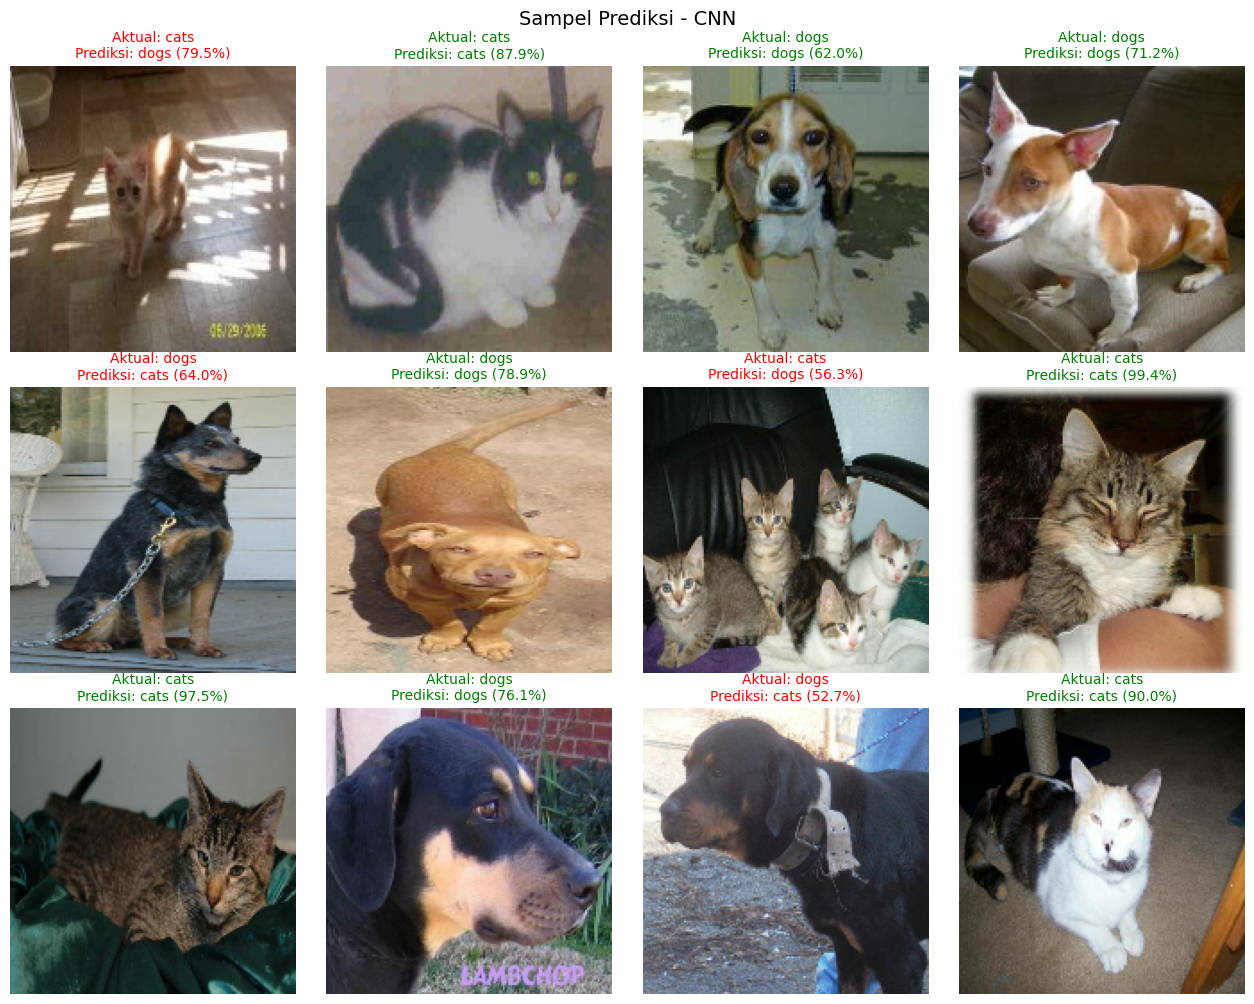

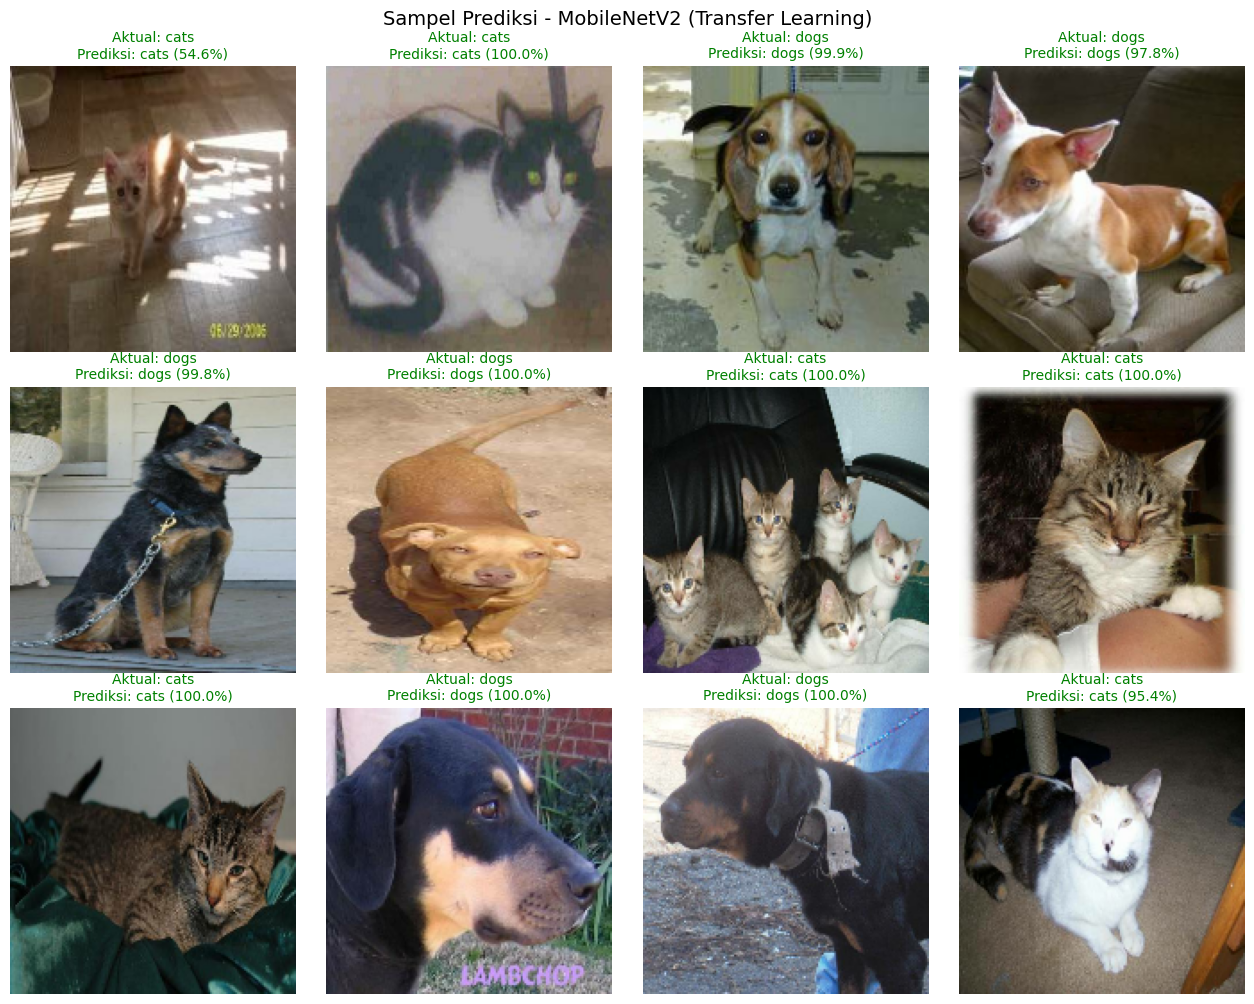

In [13]:
# ----- 8a. Sampel prediksi acak untuk satu model -----
def show_predictions(prob, name, n=12, seed=42, fname=None):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(X_test), n, replace=False)
    cols = 4
    rows = int(np.ceil(n / cols))
    plt.figure(figsize=(3.2 * cols, 3.4 * rows))
    for i, k in enumerate(idx):
        cls, conf = label_conf(prob[k])
        benar = cls == y_test[k]
        plt.subplot(rows, cols, i + 1)
        plt.imshow(X_test[k])
        plt.axis("off")
        plt.title(f"Aktual: {class_names[y_test[k]]}\nPrediksi: {class_names[cls]} ({conf:.1%})",
                  color="green" if benar else "red", fontsize=10)
    plt.suptitle(f"Sampel Prediksi - {name}", fontsize=14)
    plt.tight_layout()
    if fname:
        plt.savefig(f"results/{fname}", dpi=150, bbox_inches="tight")
    plt.show()

show_predictions(prob_cnn, "CNN", fname="prediksi_cnn.png")
show_predictions(prob_tl, "MobileNetV2 (Transfer Learning)", fname="prediksi_tl.png")

CNN dari nol: 479 salah dari 2023 gambar uji


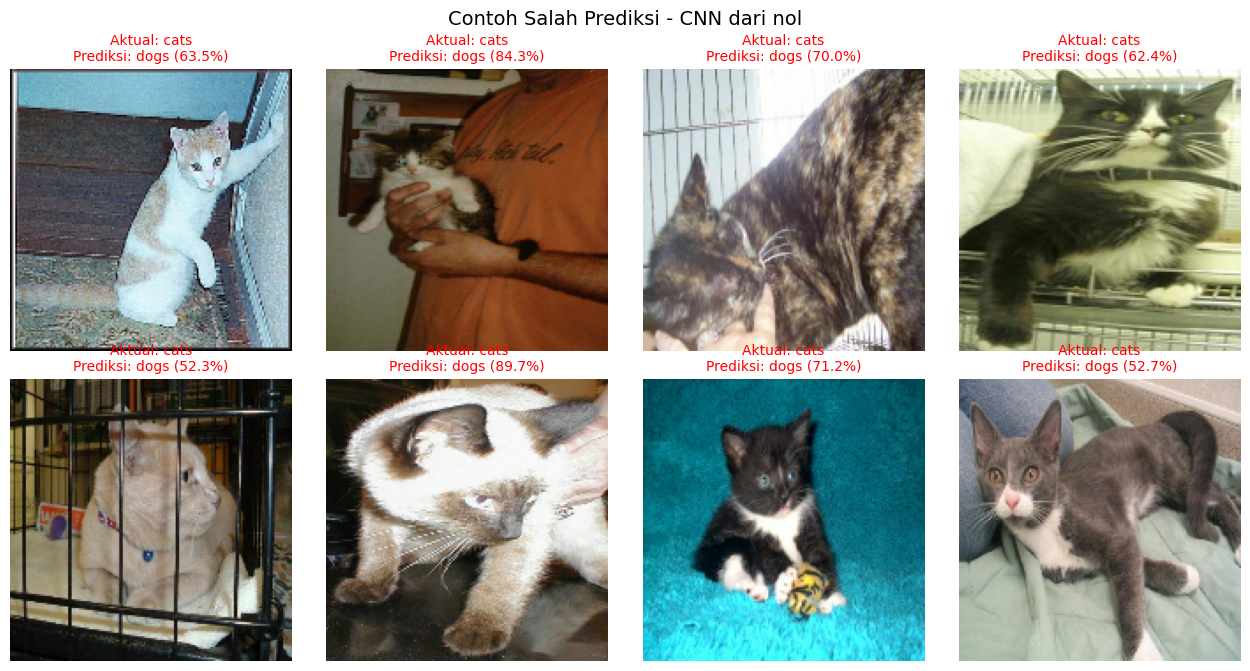

MobileNetV2 (TL): 28 salah dari 2023 gambar uji


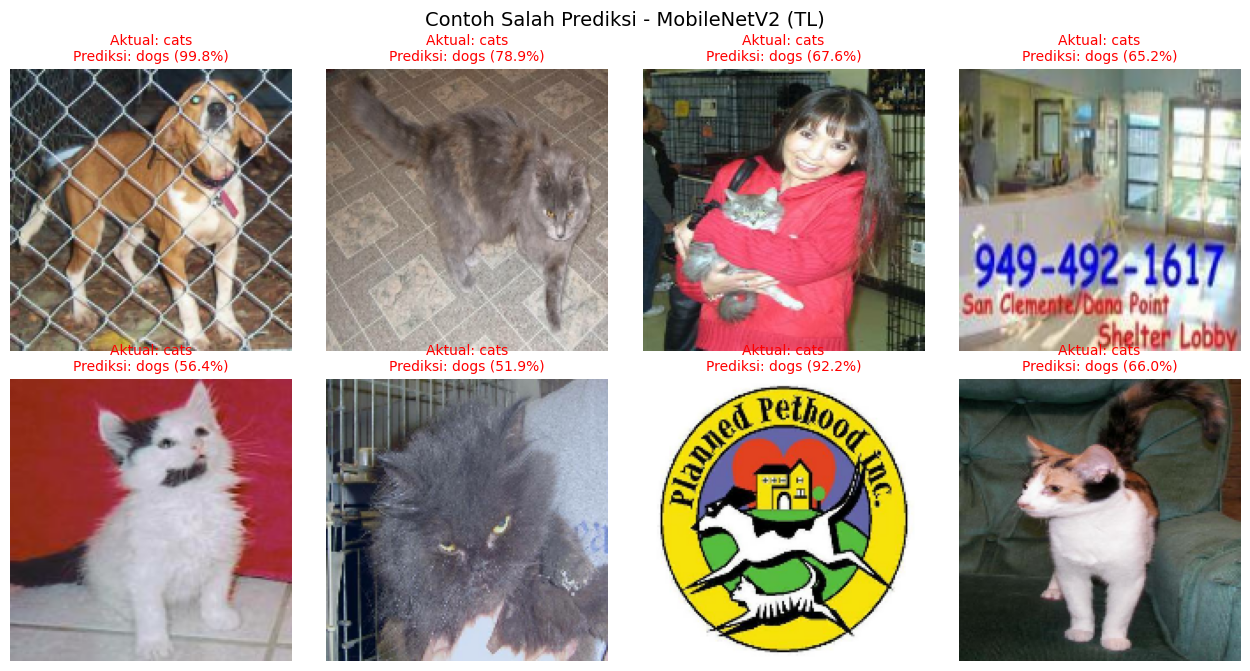

In [14]:
# ----- 8b. Gambar yang salah diprediksi -----
def show_misclassified(prob, pred, name, n=8, fname=None):
    salah = np.where(pred != y_test)[0]
    print(f"{name}: {len(salah)} salah dari {len(y_test)} gambar uji")
    if len(salah) == 0:
        return
    salah = salah[:n]
    cols = 4
    rows = int(np.ceil(len(salah) / cols))
    plt.figure(figsize=(3.2 * cols, 3.4 * rows))
    for i, k in enumerate(salah):
        cls, conf = label_conf(prob[k])
        plt.subplot(rows, cols, i + 1)
        plt.imshow(X_test[k])
        plt.axis("off")
        plt.title(f"Aktual: {class_names[y_test[k]]}\nPrediksi: {class_names[cls]} ({conf:.1%})",
                  color="red", fontsize=10)
    plt.suptitle(f"Contoh Salah Prediksi - {name}", fontsize=14)
    plt.tight_layout()
    if fname:
        plt.savefig(f"results/{fname}", dpi=150, bbox_inches="tight")
    plt.show()

show_misclassified(prob_cnn, pred_cnn, "CNN dari nol", fname="salah_cnn.png")
show_misclassified(prob_tl, pred_tl, "MobileNetV2 (TL)", fname="salah_tl.png")


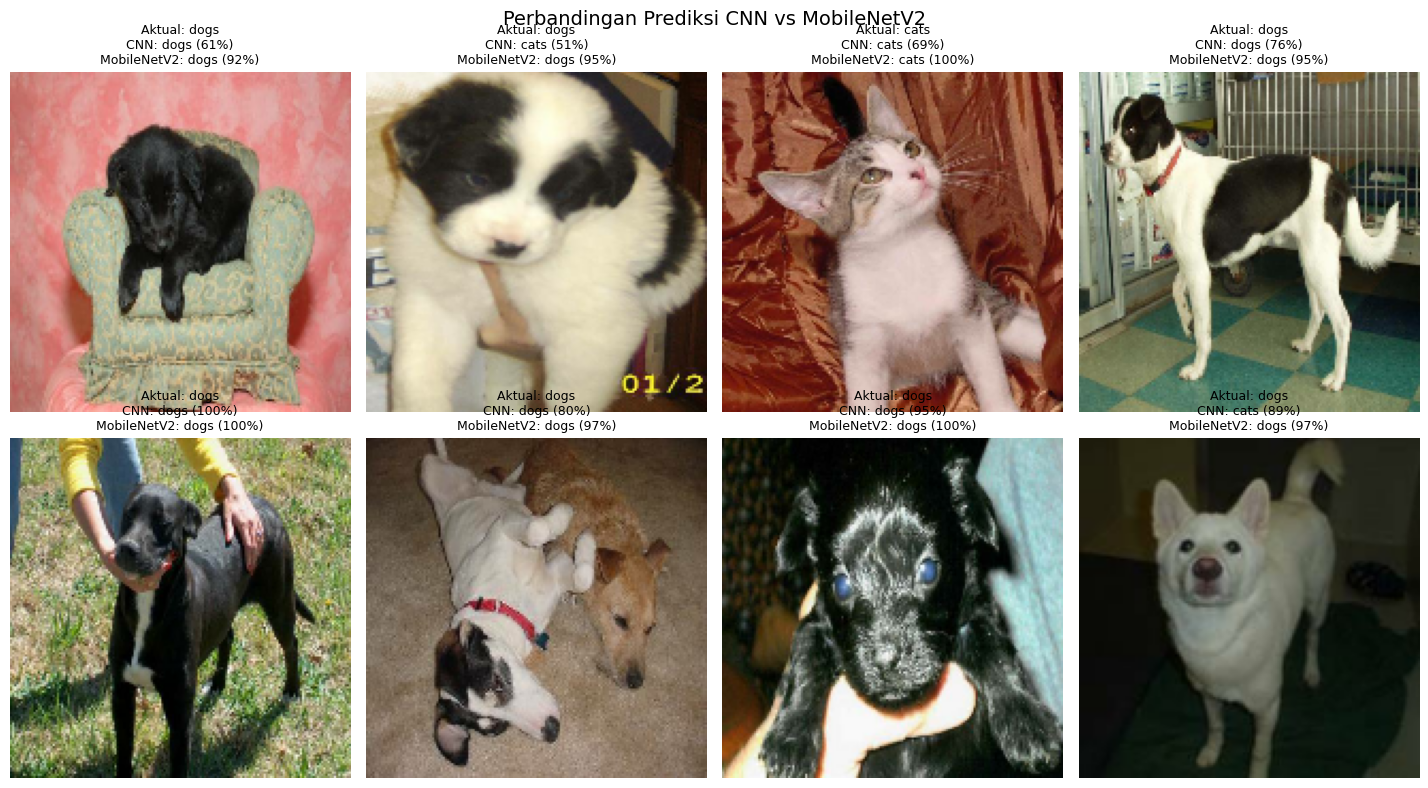

In [15]:
# ----- 8c. Perbandingan kedua model pada gambar yang sama -----
def compare_models(n=8, seed=7, fname="perbandingan_model.png"):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(X_test), n, replace=False)
    cols = 4
    rows = int(np.ceil(n / cols))
    plt.figure(figsize=(3.6 * cols, 4 * rows))
    for i, k in enumerate(idx):
        c1, f1 = label_conf(prob_cnn[k])
        c2, f2 = label_conf(prob_tl[k])
        plt.subplot(rows, cols, i + 1)
        plt.imshow(X_test[k])
        plt.axis("off")
        plt.title(f"Aktual: {class_names[y_test[k]]}\n"
                  f"CNN: {class_names[c1]} ({f1:.0%})\n"
                  f"MobileNetV2: {class_names[c2]} ({f2:.0%})", fontsize=9)
    plt.suptitle("Perbandingan Prediksi CNN vs MobileNetV2", fontsize=14)
    plt.tight_layout()
    plt.savefig(f"results/{fname}", dpi=150, bbox_inches="tight")
    plt.show()

compare_models()
